# Etapa 6: Gradient boosting

Entrada: a mesma matriz de features e os mesmos splits do notebook 03 (`modeling.prepare`).

O **gradient boosting** também combina muitas árvores, mas em sequência: cada árvore nova é treinada para corrigir o erro que as anteriores ainda cometem, e a previsão é a soma de todas, cada uma multiplicada pela taxa de aprendizado. Na Random Forest, as árvores votam de forma independente; aqui, cada uma depende das anteriores.

A versão usada é a por histogramas (`HistGradientBoostingClassifier`): antes de procurar cortes, cada atributo é agrupado em até 255 faixas, o que deixa o treino rápido em bases deste tamanho.

No notebook 03 o gradient boosting entrava só como teto, com os hiperparâmetros padrão. Aqui ele é ajustado e avaliado no cenário escolhido: descritores + SMILES, split agrupado.

O código fica em `src/gradient_boosting.py`; a busca e a avaliação são as de `src/modeling.py`.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import gradient_boosting as gb, modeling, plots
from src.config import FINAL_CSV

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)
print("X:", dados.X.shape, "| classes:", dados.y.nunique())

X: (27476, 17) | classes: 4


## 1. Busca de hiperparâmetros

300 iterações fixas e a mesma validação cruzada agrupada da árvore de decisão. O grid tem 9 combinações:

- `learning_rate`: 0,1, 0,2, 0,3 (quanto cada árvore nova corrige);
- `max_leaf_nodes`: 31, 63, 127 (o tamanho de cada árvore).

Uma primeira rodada com taxas de 0,05 a 0,2 e de 15 a 63 folhas escolheu o canto do grid (0,2 e 63). O grid foi deslocado para que a escolha caísse dentro dele.

A parada antecipada (`early_stopping`) fica desligada. Ela separa uma validação aleatória do treino, que deixaria gêmeas de descritores dos dois lados e pararia no ponto errado.

In [2]:
busca, boosting = modeling.tune_chosen(dados, gb.estimator(dados.seed), gb.PARAM_GRID)
busca

,learning_rate,max_leaf_nodes,acurácia CV,desvio CV,segundos por ajuste
0,0.2,63,0.961,0.002,23.8
1,0.3,63,0.960,0.002,16.3
2,0.1,63,0.960,0.002,29.6
3,0.1,127,0.960,0.003,43.1
4,0.2,127,0.960,0.003,27.0
5,0.3,31,0.960,0.001,14.7
6,0.2,31,0.959,0.002,15.0
7,0.3,127,0.959,0.003,16.5
8,0.1,31,0.957,0.001,14.7


In [3]:
params = modeling.chosen_params(boosting, gb.PARAM_GRID)
print("parâmetros escolhidos:", params)
pd.DataFrame({"padrão (notebook 03)": modeling.reference_models(dados, only=["HistGradientBoosting"]).iloc[0],
              "ajustado": pd.Series(modeling.test_scores(boosting, dados))})

parâmetros escolhidos: {'learning_rate': 0.2, 'max_leaf_nodes': 63}


,padrão (notebook 03),ajustado
acurácia teste,0.947,0.965
F1 macro teste,0.946,0.965


O grid é quase plano: as 9 combinações ficam entre 0,957 e 0,961 de validação, todas dentro de 2 desvios uma da outra. Árvores de 63 folhas aparecem nas três primeiras posições; a taxa de aprendizado quase não importa. A busca escolhe taxa 0,2 com 63 folhas.

Desta vez o ajuste faz diferença no teste: 0,965 contra 0,947 do padrão, **1,8 ponto a mais**. O ganho vem menos dos dois parâmetros do grid e mais do que mudou junto. O padrão do scikit-learn usa só 100 iterações e liga a parada antecipada em bases com mais de 10 mil linhas, com uma validação aleatória de 10% do treino. Aqui são 300 iterações e sem parada antecipada.

## 2. Quantas iterações

O modelo escolhido é treinado num fold de validação agrupado tirado do treino, e `staged_predict` dá a previsão depois de cada iteração. O teste não é usado.

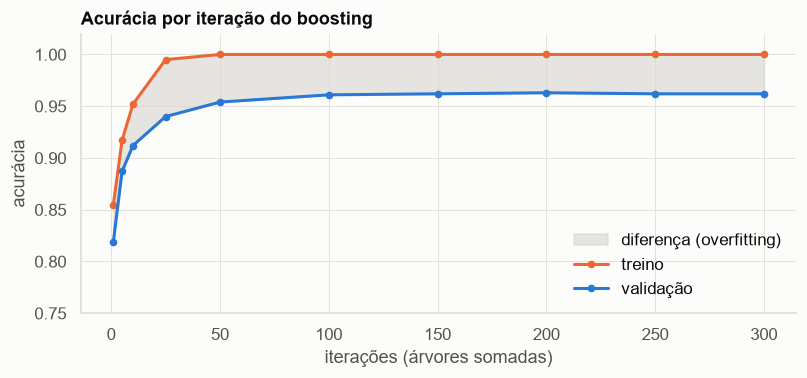

iterações,1,5,10,25,50,100,150,200,250,300
treino,0.855,0.917,0.952,0.995,1.000,1.000,1.000,1.000,1.000,1.000
validação,0.819,0.887,0.912,0.940,0.954,0.961,0.962,0.963,0.962,0.962


In [4]:
curva = gb.iterations_curve(dados, params)
plots.iterations_curve(curva)
curva.T

O treino chega a 100% de acerto com 50 iterações, mas a validação continua subindo depois disso: 0,954 com 50, 0,961 com 100 e 0,963 com 200. Depois fica plana até 300. Ao contrário da árvore de decisão, o boosting decora o treino sem perder generalização: mesmo depois que o treino não tem mais o que corrigir, as árvores novas ainda aumentam a margem entre as classes, e a validação melhora.

As 300 iterações bastam. A curva não cai no fim, então a parada antecipada não teria evitado overfitting; ela só teria parado mais cedo, com o risco de parar no ponto errado por causa das gêmeas de descritores.

## 3. Avaliação no conjunto de teste

In [5]:
relatorio, matriz = modeling.evaluation(boosting, dados)
relatorio

,precisão,revocação,F1,linhas
EGFR,0.955,0.968,0.962,1612.000
BACE1,0.975,0.964,0.969,1463.000
DRD2,0.974,0.971,0.972,1307.000
HDAC1,0.957,0.956,0.956,1114.000
accuracy,0.965,0.965,0.965,0.965
macro avg,0.965,0.965,0.965,5496.000


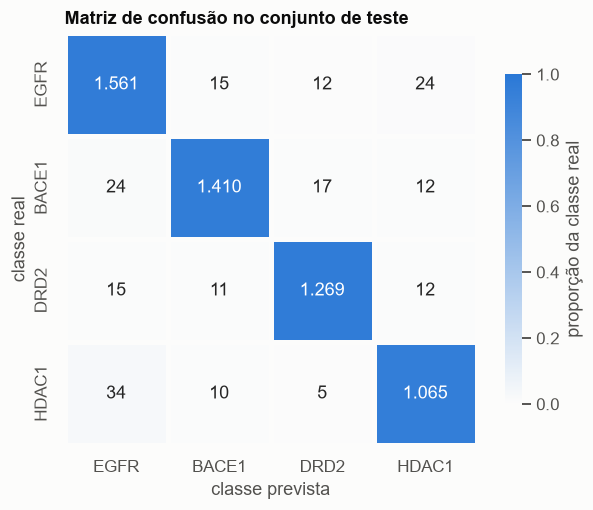

In [6]:
plots.confusion_matrix(matriz)

Acurácia de 0,965 e F1 macro de 0,965: o melhor resultado entre os modelos com a seed 42, 6,8 pontos acima da árvore de decisão (0,897) e 1,6 ponto acima da Random Forest ajustada (0,949). A ordem das classes é a de sempre: DRD2 e BACE1 as mais fáceis (F1 0,972 e 0,969), HDAC1 a mais difícil (0,956).

## 4. Importância das features

O gradient boosting por histogramas não calcula importância por impureza, então só aparece a importância por permutação, medida no teste.

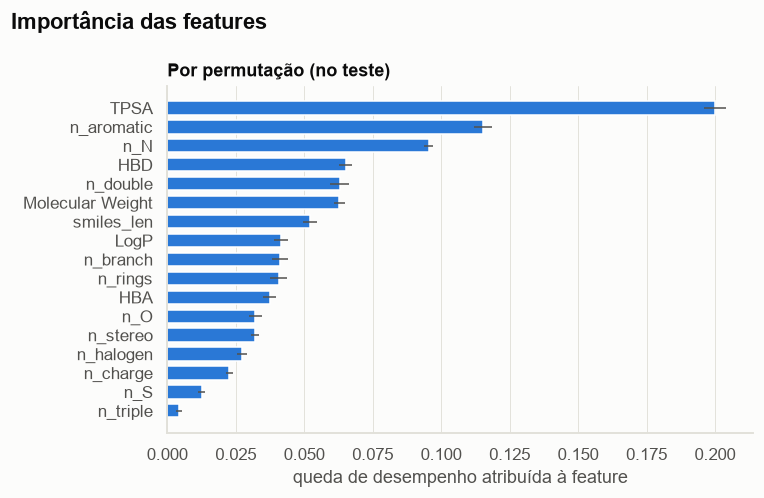

In [7]:
plots.feature_importances(modeling.importances(boosting, dados))

TPSA lidera com folga: embaralhar o atributo derruba a acurácia em 20 pontos. Depois vêm `n_aromatic` (11,5 pontos) e `n_N` (9,5 pontos), que sobe para o terceiro lugar; na árvore de decisão e na Random Forest, o terceiro era HBD. Como cada árvore do boosting corrige o erro das anteriores, as últimas árvores se especializam nos casos difíceis, e a contagem de nitrogênios parece ajudar nesses casos.

Os valores ficam entre os da Random Tree e os da Random Forest. O boosting usa todos os atributos em cada nó, então não aprende rotas alternativas como a floresta, e depende mais de cada atributo.

## 5. O modelo sabe quando está em dúvida?

In [8]:
modeling.confidence_table(boosting, dados, top_label="acima de 99,9%")

,previsões,% do teste,acurácia
faixa,,,
até 50%,4,0.1,0.250
50-70%,46,0.8,0.457
70-90%,114,2.1,0.526
90-100%,428,7.8,0.839
"acima de 99,9%",4904,89.2,0.992


O boosting é o oposto da floresta: **confiante demais**. 89,2% das previsões saem com mais de 99,9% de confiança e acertam 99,2% das vezes. Mas essa faixa ainda tem 39 dos 191 erros, cerca de 20%. Nenhum limiar de confiança separa todos os erros: abaixo de 90% de confiança há 164 previsões (3% do teste), metade delas erradas, mas elas somam só cerca de 80 erros.

Na prática, a confiança do boosting ajuda a achar parte dos erros, mas bem menos que a da floresta, onde 91% dos erros ficavam abaixo de 70% de confiança. Somar 300 árvores que corrigem umas às outras empurra as probabilidades para os extremos.

## 6. Análise de erro

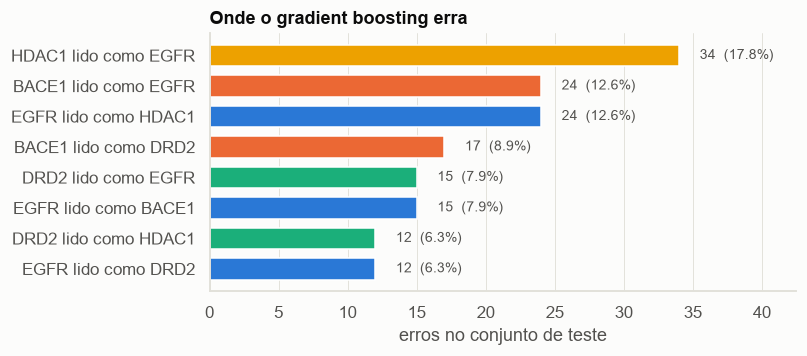

,real,prevista,erros,% dos erros,% da classe real
0,HDAC1,EGFR,34,17.8,3.1
1,BACE1,EGFR,24,12.6,1.6
2,EGFR,HDAC1,24,12.6,1.5
3,BACE1,DRD2,17,8.9,1.2
4,DRD2,EGFR,15,7.9,1.1
5,EGFR,BACE1,15,7.9,0.9


In [9]:
erros = modeling.error_overview(boosting, dados)
plots.error_pairs(erros, title="Onde o gradient boosting erra")
erros.head(6)

191 erros, contra 280 da Random Forest e cerca de 570 da árvore de decisão. O par HDAC1 ↔ EGFR continua no topo, com 30,4% dos erros nos dois sentidos: a mesma proporção dos outros modelos. Nenhum modelo resolve essa confusão, porque ela vem da representação por contagem de caracteres.

## 7. Resumo

| Cenário (descritores + SMILES, split agrupado) | Acurácia no teste |
|---|---|
| Árvore de decisão (notebook 03) | 0,897 |
| Gradient boosting padrão | 0,947 |
| Gradient boosting ajustado (taxa 0,2, 63 folhas, 300 iterações) | 0,965 |

- **O melhor modelo da seed 42.** 6,8 pontos acima da árvore e 1,6 acima da Random Forest ajustada. Os erros caem para um terço dos da árvore.
- **Aqui o ajuste importa.** 1,8 ponto sobre o padrão, que usa só 100 iterações e uma parada antecipada com validação aleatória.
- **O boosting decora o treino sem perder generalização.** O treino chega a 100% com 50 iterações e a validação ainda sobe até 200.
- **A confiança é exagerada.** Quase 90% das previsões dizem mais de 99,9%, e essa faixa ainda guarda 20% dos erros. A floresta é mais honesta sobre a própria dúvida.
- **O preço é a legibilidade.** Como na floresta, não há regras para ler; a previsão é a soma de 300 árvores.

O notebook 07 compara todos os modelos com 10 seeds, para separar diferença real de sorte do split.